# 5. Dataset filtering, paper summary reproduction and `cv0` model evaluation

## tl;dr

Applying the standard quality filters in `lc_qspr.preprocessing` to the 97,244-record descriptor table retains **46,848 molecules**. Recomputing classification and transition-temperature metrics from the 43,889-molecule 5-fold cross-validation table reproduces `paper_summary.csv` identically. Evaluating the distributed `cv0` CatBoost and GATv2Conv checkpoints on the matched `cv0` validation split (9,369 molecules) provides a direct comparison across all 17 chiral-separated phase targets and transition temperatures.

## Context & Methods

This notebook documents the quality-control filters applied before model training, verifies the published 5-fold cross-validation summary table, visualises the relationship between positive sample count and phase classification F1, and evaluates both distributed pretrained model families (CatBoost and GATv2Conv) on the `cv0` cross-validation fold.

### Key Assumptions

Source tables and molecule-level prediction files are treated as read-only inputs, and results are reported through aggregate cohort counts and summary evaluation tables.

### 1. Configure paths and imports

**Caution.** Verify that the descriptor database, reference summary tables and pretrained checkpoints share the same preprocessing and target definitions before comparing metrics.

**Extension.** Adjust the relative directory paths below when validating an external descriptor table or custom model checkpoints.

In [1]:
from pathlib import Path
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from torch_geometric.loader import DataLoader

from lc_qspr.constants import (
    ABSOLUTE_ZERO_C,
    CHIRAL_PHASE_TYPES,
    PHASE_TARGETS,
    PHASE_TYPES,
    TEMPERATURE_TARGETS,
)
from lc_qspr.evaluation import (
    classification_summary,
    cross_validation_splits,
    temperature_summary,
)
from lc_qspr.gnn import LiquidCrystalGraphDataset, load_gnn, predict_gnn_loader
from lc_qspr.prediction import CatBoostPredictor
from lc_qspr.preprocessing import (
    filter_training_table,
    read_table,
    separate_chiral_phases,
)

warnings.filterwarnings("ignore")

MIN_CARBON_AND_NITROGEN = 12
MAX_VALID_TEMPERATURE_C = 800
SUSPICIOUS_PHASE_TOKENS = ("?", " 0 ", "X", "S", "no", "un", "ex")

PROJECT_ROOT = Path("..") if Path.cwd().name == "notebooks" else Path(".")
DATA_DIR = PROJECT_ROOT / "data" / "processed"
PAPER_RESULTS_DIR = PROJECT_ROOT / "paper" / "results"
MODEL_DIR = PROJECT_ROOT / "models"

PARQUET_PATH = DATA_DIR / "LiqCryst52.parquet"
PAPER_SUMMARY_PATH = PAPER_RESULTS_DIR / "paper_summary.csv"
PAPER_DETAILED_PATH = PAPER_RESULTS_DIR / "paper_GATv2Conv.csv"

device = torch.device(
    "mps"
    if torch.backends.mps.is_available()
    else ("cuda" if torch.cuda.is_available() else "cpu")
)

print(f"Parquet dataset available : {PARQUET_PATH.exists()}")
print(f"Paper summary available   : {PAPER_SUMMARY_PATH.exists()}")
print(f"Paper detailed available  : {PAPER_DETAILED_PATH.exists()}")
print(f"Model directory available : {MODEL_DIR.exists()}")
print(f"Inference device          : {device}")

Parquet dataset available : True
Paper summary available   : True
Paper detailed available  : True
Model directory available : True
Inference device          : mps


### 2. Load the descriptor table and inspect aggregate dimensions

**Caution.** Loading the full Parquet table requires several gigabytes of memory; inspect only aggregate dimensions and flag counts rather than displaying individual rows.

**Extension.** Use `lc_qspr.preprocessing.parse_phase_table` and `add_mordred_descriptors` when starting from an unparsed SMILES table.

In [2]:
raw_table = read_table(PARQUET_PATH)

print(f"Total rows in raw table   : {raw_table.shape[0]:,}")
print(f"Total columns in raw table: {raw_table.shape[1]:,}")
print("Quality-flag counts (True):")
for flag in ("exclude", "prohibited", "reentrant"):
    if flag in raw_table.columns:
        print(f"  {flag:12s}: {int(raw_table[flag].astype(bool).sum()):,}")

Total rows in raw table   : 97,244
Total columns in raw table: 1,657
Quality-flag counts (True):
  exclude     : 33,966
  reentrant   : 158


### 3. Trace step-by-step dataset filtering

**Caution.** Each filtering rule alters the chemical cohort; apply `separate_chiral_phases` before `filter_training_table` so that chiral temperature bounds are checked consistently.

**Extension.** Customise `minimum_nitrogen_and_carbon` or `suspicious_tokens` in `filter_training_table` when adapting the pipeline to a different materials domain.

In [3]:
df_step = raw_table.copy()
step_records = [("0. Initial table", len(df_step), 0)]

# 1. Remove all rows sharing a duplicated SMILES string
vc = df_step["SMILES"].value_counts()
dup_smiles = vc[vc > 1].index
n_prev = len(df_step)
df_step = df_step[~df_step["SMILES"].isin(dup_smiles)]
step_records.append(("1. Remove duplicate SMILES", len(df_step), n_prev - len(df_step)))

# 2. Separate chiral phases (* phases) into dedicated binary and temperature columns
df_step, chiral_phases = separate_chiral_phases(df_step)
step_records.append(("2. Separate chiral phases (*)", len(df_step), 0))
print("Chiral phases separated:", chiral_phases)

# 3. Minimum heavy-atom filter (nC + nN >= 12)
n_prev = len(df_step)
df_step = df_step[(df_step["nC"] + df_step["nN"]) >= MIN_CARBON_AND_NITROGEN]
step_records.append((f"3. Require nC + nN >= {MIN_CARBON_AND_NITROGEN}", len(df_step), n_prev - len(df_step)))

# 4. Quality flags: exclude, prohibited, reentrant
for flag in ("exclude", "prohibited", "reentrant"):
    if flag in df_step.columns:
        n_prev = len(df_step)
        df_step = df_step[~df_step[flag].astype(bool)]
        step_records.append((f"4. Drop flag '{flag}'", len(df_step), n_prev - len(df_step)))

# 5. Standard clearing transition (Clearingtype == 1)
if "Clearingtype" in df_step.columns:
    n_prev = len(df_step)
    df_step = df_step[df_step["Clearingtype"] == 1]
    step_records.append(("5. Require Clearingtype == 1", len(df_step), n_prev - len(df_step)))

# 6. Exclude physically inconsistent transitions (Tm > Tp)
n_prev = len(df_step)
for phase in PHASE_TYPES:
    lower, upper = f"{phase}m", f"{phase}p"
    if lower in df_step.columns and upper in df_step.columns:
        df_step = df_step[~(df_step[lower] > df_step[upper])]
step_records.append(("6. Drop Tm > Tp inconsistencies", len(df_step), n_prev - len(df_step)))

# 7. Replace out-of-range sentinel temperatures with NaN
for target in TEMPERATURE_TARGETS:
    if target in df_step.columns:
        invalid = (
            (df_step[target] < ABSOLUTE_ZERO_C)
            | (df_step[target] >= MAX_VALID_TEMPERATURE_C)
            | (df_step[target] == 0)
        )
        df_step.loc[invalid, target] = np.nan
step_records.append(("7. Replace sentinel temperatures with NaN", len(df_step), 0))

# 8. Exclude rows whose raw Phases text contains suspicious tokens
n_prev = len(df_step)
for token in SUSPICIOUS_PHASE_TOKENS:
    df_step = df_step[~df_step["Phases"].astype(str).str.contains(token, regex=False, na=False)]
step_records.append(("8. Drop suspicious tokens in Phases", len(df_step), n_prev - len(df_step)))

# 9. Require at least one valid transition temperature
n_prev = len(df_step)
temp_cols = [c for c in TEMPERATURE_TARGETS if c in df_step.columns]
df_step = df_step[~df_step[temp_cols].min(axis=1).isna()]
step_records.append(("9. Require >= 1 valid temperature", len(df_step), n_prev - len(df_step)))

step_summary_df = pd.DataFrame(
    step_records, columns=["Filtering step", "Remaining molecules", "Dropped at step"]
)
display(step_summary_df)

# Verify exact equivalence with the single-call package pipeline
separated_table, _ = separate_chiral_phases(raw_table)
filtered_table = filter_training_table(separated_table)

print(f"Step-by-step remaining molecules : {len(df_step):,}")
print(f"filter_training_table molecules  : {len(filtered_table):,}")
assert len(df_step) == len(filtered_table) == 46848
assert df_step.index.equals(filtered_table.index)
print("Verification passed: 46,848 molecules retained with identical indices.")

Chiral phases separated: ['N*', 'C*', 'E*', 'F*', 'I*']


,Filtering step,Remaining molecules,Dropped at step
0,0. Initial table,97244,0
1,1. Remove duplicate SMILES,95576,1668
2,2. Separate chiral phases (*),95576,0
3,3. Require nC + nN >= 12,94070,1506
4,4. Drop flag 'exclude',60925,33145
5,4. Drop flag 'reentrant',60824,101
6,5. Require Clearingtype == 1,57456,3368
7,6. Drop Tm > Tp inconsistencies,57256,200
8,7. Replace sentinel temperatures with NaN,57256,0
9,8. Drop suspicious tokens in Phases,47609,9647


Step-by-step remaining molecules : 46,848
filter_training_table molecules  : 46,848
Verification passed: 46,848 molecules retained with identical indices.


### 4. Visualise molecule retention across filtering stages

**Caution.** Requiring a standard clearing transition (`Clearingtype == 1`) accounts for the largest single reduction because many source entries lack a standard isotropic clearing point.

**Extension.** Inspect the dropped subsets separately when investigating non-standard mesogens or decomposing compounds.

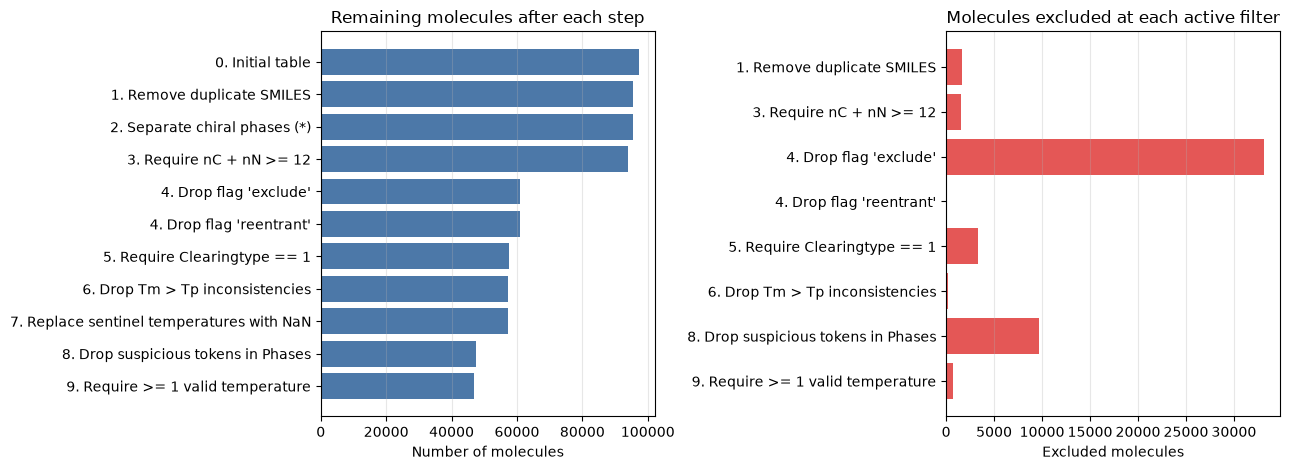

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

ax1.barh(
    step_summary_df["Filtering step"][::-1],
    step_summary_df["Remaining molecules"][::-1],
    color="#4C78A8",
)
ax1.set_title("Remaining molecules after each step")
ax1.set_xlabel("Number of molecules")
ax1.grid(axis="x", alpha=0.3)

dropped_steps = step_summary_df[step_summary_df["Dropped at step"] > 0]
ax2.barh(
    dropped_steps["Filtering step"][::-1],
    dropped_steps["Dropped at step"][::-1],
    color="#E45756",
)
ax2.set_title("Molecules excluded at each active filter")
ax2.set_xlabel("Excluded molecules")
ax2.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

### 5. Reproduce `paper_summary.csv` from the 5-fold GNN predictions

**Caution.** In the saved paper results, discotic columns are labelled `Dtype`, `Dp` and `Dm` in the detailed table and `Dh` in `paper_summary.csv`; align the index label before comparing numerically.

**Extension.** Pass any out-of-fold prediction table with `true_`, `pred_` and `error_` columns to `classification_summary` to generate an equivalent benchmark table.

In [5]:
paper_summary = pd.read_csv(PAPER_SUMMARY_PATH).set_index("type")
detailed_results = pd.read_csv(PAPER_DETAILED_PATH, low_memory=False)

print(f"5-fold prediction table shape: {detailed_results.shape}")

paper_phase_targets = [
    f"{p}type" if f"true_{p}type" in detailed_results.columns else "Dtype"
    for p in paper_summary.index
]
recomputed_summary = classification_summary(detailed_results, paper_phase_targets)

comparison_cols = [
    "npos",
    "N",
    "accuracy",
    "recall",
    "precision",
    "f1",
    "Tp_mean",
    "Tp_std",
    "Tm_mean",
    "Tm_std",
]
recomputed_display = recomputed_summary[comparison_cols].rename(columns={"accuracy": "acc"})
aligned_recomputed = recomputed_display.rename(index={"D": "Dh"}).loc[paper_summary.index]

print("Recomputed summary from paper_GATv2Conv.csv:")
display(aligned_recomputed)

print("Published paper_summary.csv:")
display(paper_summary)

max_abs_diff = (aligned_recomputed - paper_summary[recomputed_display.columns]).abs().max()
print("Maximum absolute difference per column:")
display(max_abs_diff.to_frame(name="max_abs_diff").T)

assert (aligned_recomputed["npos"] == paper_summary["npos"]).all()
assert (aligned_recomputed["N"] == paper_summary["N"]).all()
assert np.allclose(aligned_recomputed["acc"], paper_summary["acc"], atol=1e-4)
assert np.allclose(aligned_recomputed["f1"], paper_summary["f1"], atol=1e-4)
assert np.allclose(
    aligned_recomputed["Tp_mean"].dropna(),
    paper_summary["Tp_mean"].dropna(),
    atol=1e-4,
)
assert np.allclose(
    aligned_recomputed["Tm_mean"].dropna(),
    paper_summary["Tm_mean"].dropna(),
    atol=1e-4,
)
print("Verification passed: paper_summary.csv is reproduced within rounding precision.")

5-fold prediction table shape: (43889, 109)


Recomputed summary from paper_GATv2Conv.csv:


,npos,N,acc,recall,precision,f1,Tp_mean,Tp_std,Tm_mean,Tm_std
type,,,,,,,,,,
N,20662,43889,0.924081,0.920288,0.918599,0.919443,7.388669,11.440307,11.048438,12.523904
A,9531,43889,0.935679,0.847130,0.855297,0.851194,8.395594,12.281560,10.111967,12.273427
B,1710,43889,0.979380,0.685380,0.761533,0.721453,10.722627,12.779174,13.325514,15.315523
C,6444,43889,0.961084,0.868870,0.866450,0.867658,7.995681,11.007055,8.773100,10.651999
E,392,43889,0.994805,0.627551,0.750000,0.683333,10.109548,12.959335,14.087394,15.012554
F,307,43889,0.996833,0.719870,0.806569,0.760757,6.200850,8.644574,9.111894,11.469691
G,328,43889,0.995397,0.631098,0.718750,0.672078,8.542749,11.901828,10.090222,10.921457
H,52,43889,0.999066,0.557692,0.617021,0.585859,13.109982,18.969455,14.037840,13.850166
I,274,43889,0.997015,0.748175,0.767790,0.757856,6.134303,16.290632,10.118507,18.049800


Published paper_summary.csv:


,npos,N,acc,recall,precision,f1,Tp_mean,Tp_std,Tm_mean,Tm_std
type,,,,,,,,,,
N,20662,43889,0.92408,0.92029,0.91860,0.91944,7.388669,11.440307,11.048438,12.523904
A,9531,43889,0.93568,0.84713,0.85530,0.85119,8.395594,12.281560,10.111967,12.273427
B,1710,43889,0.97938,0.68538,0.76153,0.72145,10.722627,12.779174,13.325514,15.315523
C,6444,43889,0.96108,0.86887,0.86645,0.86766,7.995681,11.007055,8.773100,10.651999
E,392,43889,0.99481,0.62755,0.75000,0.68333,10.109548,12.959335,14.087394,15.012554
F,307,43889,0.99683,0.71987,0.80657,0.76076,6.200850,8.644574,9.111894,11.469691
G,328,43889,0.99540,0.63110,0.71875,0.67208,8.542749,11.901828,10.090222,10.921457
H,52,43889,0.99907,0.55769,0.61702,0.58586,13.109982,18.969455,14.037840,13.850166
I,274,43889,0.99702,0.74818,0.76779,0.75786,6.134303,16.290632,10.118507,18.049800


Maximum absolute difference per column:


,npos,N,acc,recall,precision,f1,Tp_mean,Tp_std,Tm_mean,Tm_std
max_abs_diff,0.0,0.0,0.000005,0.000005,0.000003,0.000004,1.776357e-15,1.953993e-14,1.776357e-15,1.776357e-14


Verification passed: paper_summary.csv is reproduced within rounding precision.


### 6. Plot class frequency against phase-classification F1

**Caution.** Overall accuracy stays near 1.0 for rare phases because negative examples dominate; always evaluate phase classifiers against positive sample count (`npos`) and F1.

**Extension.** Stratify error analyses by positive class count when comparing loss functions such as focal loss and class-weighted cross-entropy.

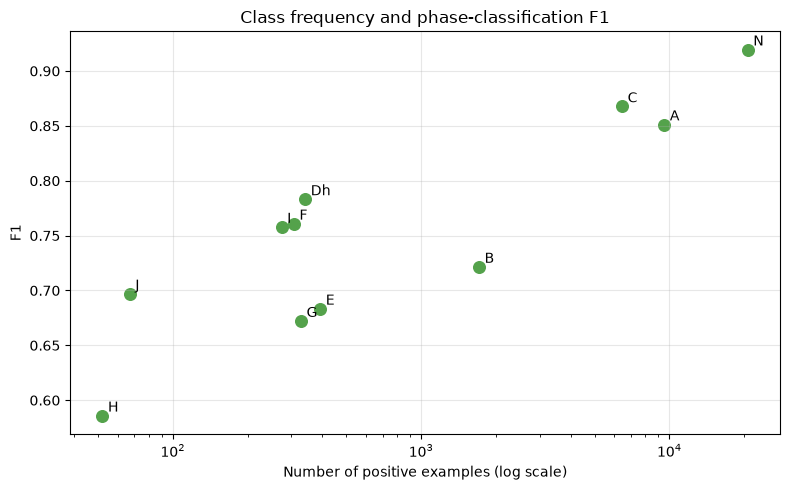

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(
    paper_summary["npos"],
    paper_summary["f1"],
    color="#54A24B",
    s=70,
)
for phase_name, row in paper_summary.iterrows():
    ax.annotate(
        phase_name,
        (row["npos"], row["f1"]),
        xytext=(4, 3),
        textcoords="offset points",
    )
ax.set_xscale("log")
ax.set_xlabel("Number of positive examples (log scale)")
ax.set_ylabel("F1")
ax.set_title("Class frequency and phase-classification F1")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 7. Reconcile cohort sizes and construct the `cv0` evaluation split

**Caution.** The distributed pretrained checkpoints correspond to fold 0 (`cv0`) of the 5-fold cross-validation scheme; evaluating on the full dataset mixes training and validation molecules, so evaluation must be restricted to the `cv0` test split.

**Extension.** Iterate across all five folds in `splits` when evaluating a complete set of out-of-fold checkpoints.

In [7]:
paper_ids = set(detailed_results["ID"])
filtered_ids = set(filtered_table.index)
extra_df = filtered_table.loc[list(filtered_ids - paper_ids)]
multi_component_count = int(extra_df["SMILES"].str.contains(r"\.", regex=True).sum())

print(f"Filtered descriptor table molecules : {len(filtered_table):,}")
print(f"Paper 5-fold GNN cohort molecules   : {len(detailed_results):,}")
print(f"Molecules in both cohorts           : {len(filtered_ids & paper_ids):,}")
print(f"Difference (filtered - paper cohort): {len(extra_df):,} (including {multi_component_count:,} multi-component '.' SMILES)")

phase_target_names = tuple(f"{p}type" for p in CHIRAL_PHASE_TYPES)
splits = cross_validation_splits(
    filtered_table,
    phase_target_names,
    mode="classification",
    n_splits=5,
    random_state=42,
)
cv0_train_idx, cv0_test_idx = splits[0]
cv0_table = filtered_table.iloc[cv0_test_idx].copy()

print(f"\ncv0 training fold molecules         : {len(cv0_train_idx):,}")
print(f"cv0 evaluation fold molecules       : {len(cv0_table):,}")

Filtered descriptor table molecules : 46,848
Paper 5-fold GNN cohort molecules   : 43,889
Molecules in both cohorts           : 43,843
Difference (filtered - paper cohort): 3,005 (including 1,453 multi-component '.' SMILES)



cv0 training fold molecules         : 37,479
cv0 evaluation fold molecules       : 9,369


### 8. Evaluate the pretrained CatBoost models on `cv0`

**Caution.** Ensure the feature columns passed to `CatBoostPredictor` follow the exact order in `predictor.descriptor_names`.

**Extension.** Supply custom `phase_model` and `temperature_model` paths to `CatBoostPredictor.from_directory` when benchmarking newly trained CatBoost checkpoints on `cv0`.

In [8]:
predictor = CatBoostPredictor.from_directory(MODEL_DIR)
print(f"Loaded CatBoost models expecting {len(predictor.descriptor_names)} Mordred descriptors.")

t0 = time.time()
cv0_features = cv0_table.loc[:, predictor.descriptor_names]
cb_phase_probs = np.asarray(predictor.phase_model.predict_proba(cv0_features))
cb_temps = np.asarray(predictor.temperature_model.predict(cv0_features))
cb_elapsed = time.time() - t0
print(f"Completed CatBoost inference on {len(cv0_table):,} cv0 molecules in {cb_elapsed:.2f}s.")

cb_results_dict = {}
for idx, phase in enumerate(CHIRAL_PHASE_TYPES):
    cb_results_dict[f"true_{phase}type"] = cv0_table[f"{phase}type"].values
    cb_results_dict[f"pred_{phase}type"] = (cb_phase_probs[:, idx] >= 0.5).astype(int)
    cb_results_dict[f"pos_conf_{phase}type"] = cb_phase_probs[:, idx]

for idx, target in enumerate(TEMPERATURE_TARGETS):
    if target in cv0_table.columns:
        cb_results_dict[f"true_{target}"] = cv0_table[target].values
        cb_results_dict[f"pred_{target}"] = cb_temps[:, idx]
        cb_results_dict[f"error_{target}"] = np.abs(cv0_table[target].values - cb_temps[:, idx])

cb_cv0_results = pd.DataFrame(cb_results_dict, index=cv0_table.index)

main_phases = ["N", "A", "B", "C", "E", "F", "G", "H", "I", "J", "Dh"]
cb_summary_11 = classification_summary(cb_cv0_results, [f"{p}type" for p in main_phases])
cb_table_11 = cb_summary_11[comparison_cols].rename(columns={"accuracy": "acc"})

print("\nCatBoost cv0 evaluation — 11 main phases:")
display(cb_table_11)

cb_summary_all = classification_summary(cb_cv0_results, [f"{p}type" for p in CHIRAL_PHASE_TYPES])
cb_table_all = cb_summary_all[comparison_cols].rename(columns={"accuracy": "acc"})

print("\nCatBoost cv0 evaluation — all 17 chiral-separated phases:")
display(cb_table_all)

cb_temp_metrics = temperature_summary(cb_cv0_results, ["Clearing", "Melting"])
print("\nCatBoost cv0 evaluation — Clearing and Melting temperatures:")
display(cb_temp_metrics)

Loaded CatBoost models expecting 1613 Mordred descriptors.
Completed CatBoost inference on 9,369 cv0 molecules in 0.14s.



CatBoost cv0 evaluation — 11 main phases:


,npos,N,acc,recall,precision,f1,Tp_mean,Tp_std,Tm_mean,Tm_std
type,,,,,,,,,,
N,3772,9369,0.987939,0.985684,0.984379,0.985031,4.692477,7.910417,6.028232,8.494354
A,2096,9369,0.986445,0.960878,0.978145,0.969434,4.132410,7.355256,4.442777,6.929433
B,357,9369,0.995624,0.918768,0.964706,0.941176,2.626636,6.485770,2.317922,5.012741
C,876,9369,0.993276,0.950913,0.976553,0.963563,3.304958,6.828940,2.910400,5.342384
E,74,9369,0.999360,0.918919,1.000000,0.957746,2.410511,7.470652,3.160553,8.179126
F,53,9369,0.999893,0.981132,1.000000,0.990476,1.996741,3.825491,4.202420,9.686704
G,74,9369,0.999466,0.972973,0.960000,0.966443,2.488127,5.878229,3.699991,8.438186
H,12,9369,0.999787,0.833333,1.000000,0.909091,1.535410,4.225460,2.480881,6.255154
I,46,9369,0.999146,0.913043,0.913043,0.913043,2.578390,7.896939,3.181381,9.027520



CatBoost cv0 evaluation — all 17 chiral-separated phases:


,npos,N,acc,recall,precision,f1,Tp_mean,Tp_std,Tm_mean,Tm_std
type,,,,,,,,,,
N,3772,9369,0.987939,0.985684,0.984379,0.985031,4.692477,7.910417,6.028232,8.494354
A,2096,9369,0.986445,0.960878,0.978145,0.969434,4.132410,7.355256,4.442777,6.929433
B,357,9369,0.995624,0.918768,0.964706,0.941176,2.626636,6.485770,2.317922,5.012741
C,876,9369,0.993276,0.950913,0.976553,0.963563,3.304958,6.828940,2.910400,5.342384
E,74,9369,0.999360,0.918919,1.000000,0.957746,2.410511,7.470652,3.160553,8.179126
F,53,9369,0.999893,0.981132,1.000000,0.990476,1.996741,3.825491,4.202420,9.686704
G,74,9369,0.999466,0.972973,0.960000,0.966443,2.488127,5.878229,3.699991,8.438186
H,12,9369,0.999787,0.833333,1.000000,0.909091,1.535410,4.225460,2.480881,6.255154
I,46,9369,0.999146,0.913043,0.913043,0.913043,2.578390,7.896939,3.181381,9.027520



CatBoost cv0 evaluation — Clearing and Melting temperatures:


,n,mae,standard_deviation,median_absolute_error
target,,,,
Clearing,9365,7.073393,9.118243,4.517926
Melting,9366,7.228582,8.587356,5.015177


### 9. Evaluate the pretrained GNN model (`GATv2Conv_phase_temp_cv0.pt`) on `cv0`

**Caution.** Graph featurisation settings (`atom_encoding='none'`, `explicit_hydrogens=False`) must match the configuration used when `GATv2Conv_phase_temp_cv0.pt` was trained.

**Extension.** Pass a custom checkpoint path to `load_gnn` to evaluate alternative graph architectures on the identical `cv0` split.

In [9]:
gnn_classification = pd.DataFrame(0, index=cv0_table.index, columns=list(phase_target_names))
for phase in CHIRAL_PHASE_TYPES:
    col = f"{phase}type"
    if col in cv0_table.columns:
        gnn_classification[col] = (cv0_table[col] > 0).astype(int).values

gnn_regression = pd.DataFrame(0.0, index=cv0_table.index, columns=list(TEMPERATURE_TARGETS))
for target in TEMPERATURE_TARGETS:
    if target in cv0_table.columns:
        gnn_regression[target] = cv0_table[target].values

t0 = time.time()
gnn_dataset = LiquidCrystalGraphDataset(
    cv0_table["SMILES"].tolist(),
    classification_targets=gnn_classification,
    regression_targets=gnn_regression,
    atom_encoding="none",
)
t_graph = time.time() - t0
print(f"Constructed {len(gnn_dataset):,} molecular graphs for cv0 in {t_graph:.2f}s.")

gnn_checkpoint = MODEL_DIR / "GATv2Conv_phase_temp_cv0.pt"
gnn_model = load_gnn(gnn_checkpoint, map_location=device).to(device)
gnn_loader = DataLoader(gnn_dataset, batch_size=512, shuffle=False)

t1 = time.time()
gnn_cv0_results = predict_gnn_loader(
    gnn_model,
    gnn_loader,
    mode="both",
    phase_targets=phase_target_names,
    temperature_targets=TEMPERATURE_TARGETS,
    class_masks=gnn_dataset.output_channel_masks,
    device=device,
)
gnn_cv0_results.index = cv0_table.index
t_infer = time.time() - t1
print(f"Completed GNN inference on {len(cv0_table):,} cv0 molecules in {t_infer:.2f}s.")

gnn_summary_11 = classification_summary(gnn_cv0_results, [f"{p}type" for p in main_phases])
gnn_table_11 = gnn_summary_11[comparison_cols].rename(columns={"accuracy": "acc"})

print("\nGNN (GATv2Conv cv0) evaluation on cv0 — 11 main phases:")
display(gnn_table_11)

gnn_summary_all = classification_summary(gnn_cv0_results, [f"{p}type" for p in CHIRAL_PHASE_TYPES])
gnn_table_all = gnn_summary_all[comparison_cols].rename(columns={"accuracy": "acc"})

print("\nGNN (GATv2Conv cv0) evaluation on cv0 — all 17 chiral-separated phases:")
display(gnn_table_all)

gnn_temp_metrics = temperature_summary(gnn_cv0_results, ["Clearing", "Melting"])
print("\nGNN (GATv2Conv cv0) evaluation on cv0 — Clearing and Melting temperatures:")
display(gnn_temp_metrics)

Constructed 9,369 molecular graphs for cv0 in 8.33s.


Completed GNN inference on 9,369 cv0 molecules in 4.92s.

GNN (GATv2Conv cv0) evaluation on cv0 — 11 main phases:


,npos,N,acc,recall,precision,f1,Tp_mean,Tp_std,Tm_mean,Tm_std
type,,,,,,,,,,
N,3772,9369,0.957413,0.921792,0.970958,0.945736,4.969844,5.863755,6.328641,7.485087
A,2096,9369,0.963283,0.905057,0.928991,0.916868,5.900606,7.053416,6.646268,7.874106
B,357,9369,0.990607,0.826331,0.919003,0.870206,5.825241,6.979589,6.668955,7.886503
C,876,9369,0.985271,0.944064,0.902838,0.922991,5.978681,7.033893,5.546086,6.163965
E,74,9369,0.998186,0.770270,1.000000,0.870229,5.424706,5.574643,9.291900,10.580685
F,53,9369,0.998079,0.735849,0.906977,0.812500,3.908189,4.119684,6.731672,8.939023
G,74,9369,0.997011,0.648649,0.960000,0.774194,5.249479,5.835240,7.113375,6.968204
H,12,9369,0.999787,0.833333,1.000000,0.909091,6.055007,6.360894,3.417207,3.032849
I,46,9369,0.998719,0.891304,0.854167,0.872340,4.431661,4.056835,5.668438,5.149188



GNN (GATv2Conv cv0) evaluation on cv0 — all 17 chiral-separated phases:


,npos,N,acc,recall,precision,f1,Tp_mean,Tp_std,Tm_mean,Tm_std
type,,,,,,,,,,
N,3772,9369,0.957413,0.921792,0.970958,0.945736,4.969844,5.863755,6.328641,7.485087
A,2096,9369,0.963283,0.905057,0.928991,0.916868,5.900606,7.053416,6.646268,7.874106
B,357,9369,0.990607,0.826331,0.919003,0.870206,5.825241,6.979589,6.668955,7.886503
C,876,9369,0.985271,0.944064,0.902838,0.922991,5.978681,7.033893,5.546086,6.163965
E,74,9369,0.998186,0.770270,1.000000,0.870229,5.424706,5.574643,9.291900,10.580685
F,53,9369,0.998079,0.735849,0.906977,0.812500,3.908189,4.119684,6.731672,8.939023
G,74,9369,0.997011,0.648649,0.960000,0.774194,5.249479,5.835240,7.113375,6.968204
H,12,9369,0.999787,0.833333,1.000000,0.909091,6.055007,6.360894,3.417207,3.032849
I,46,9369,0.998719,0.891304,0.854167,0.872340,4.431661,4.056835,5.668438,5.149188



GNN (GATv2Conv cv0) evaluation on cv0 — Clearing and Melting temperatures:


,n,mae,standard_deviation,median_absolute_error
target,,,,
Clearing,9365,6.024262,9.141782,3.986359
Melting,9366,6.833992,9.382216,4.403782


### 10. Compare CatBoost and GNN performance on `cv0`

**Caution.** Comparing single-checkpoint metrics requires identical evaluation indices; here both models are evaluated on the exact same 9,369 `cv0` molecules.

**Extension.** Combine phase probabilities from CatBoost with temperature predictions from GNN using `combine_phase_and_temperature_results` to explore hybrid ensembles.

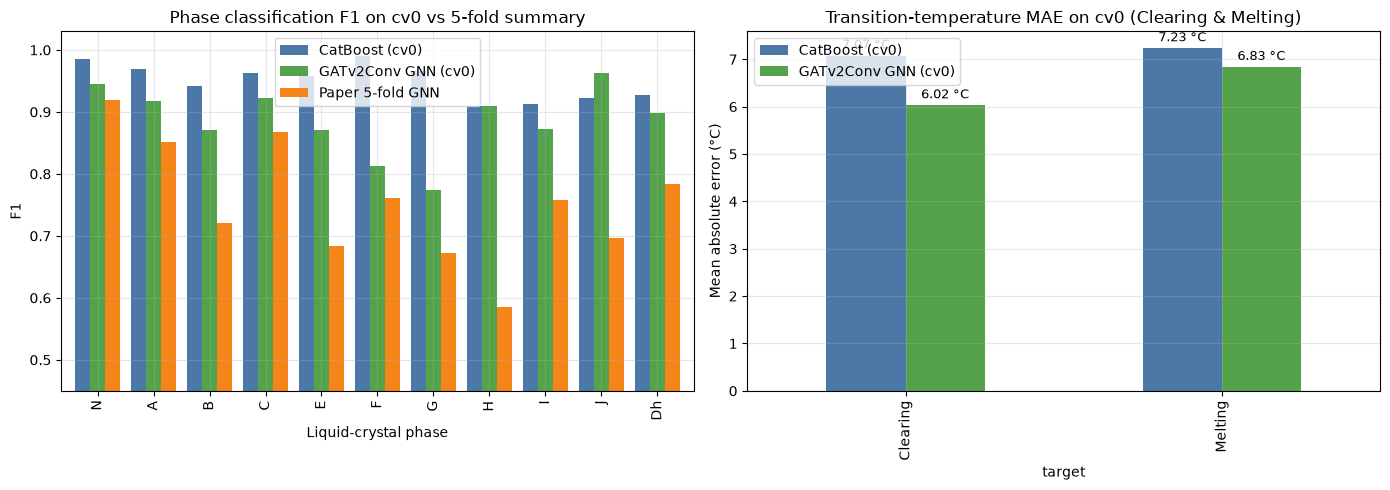

,npos_cv0,CatBoost_cv0_F1,GNN_cv0_F1,Paper_5fold_F1
type,,,,
N,3772,0.985031,0.945736,0.919443
A,2096,0.969434,0.916868,0.851194
B,357,0.941176,0.870206,0.721453
C,876,0.963563,0.922991,0.867658
E,74,0.957746,0.870229,0.683333
F,53,0.990476,0.812500,0.760757
G,74,0.966443,0.774194,0.672078
H,12,0.909091,0.909091,0.585859
I,46,0.913043,0.872340,0.757856


In [10]:
cv0_f1_comparison = pd.DataFrame(
    {
        "npos_cv0": cb_table_11["npos"],
        "CatBoost_cv0_F1": cb_table_11["f1"],
        "GNN_cv0_F1": gnn_table_11["f1"],
        "Paper_5fold_F1": aligned_recomputed["f1"],
    }
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

cv0_f1_comparison[["CatBoost_cv0_F1", "GNN_cv0_F1", "Paper_5fold_F1"]].plot.bar(
    ax=ax1,
    color=["#4C78A8", "#54A24B", "#F58518"],
    width=0.8,
)
ax1.set_title("Phase classification F1 on cv0 vs 5-fold summary")
ax1.set_ylabel("F1")
ax1.set_xlabel("Liquid-crystal phase")
ax1.set_ylim(0.45, 1.03)
ax1.grid(alpha=0.3)
ax1.legend(["CatBoost (cv0)", "GATv2Conv GNN (cv0)", "Paper 5-fold GNN"])

temp_mae_comparison = pd.DataFrame(
    {
        "CatBoost (cv0)": cb_temp_metrics["mae"],
        "GATv2Conv GNN (cv0)": gnn_temp_metrics["mae"],
    }
)
temp_mae_comparison.plot.bar(ax=ax2, color=["#4C78A8", "#54A24B"], width=0.5)
ax2.set_title("Transition-temperature MAE on cv0 (Clearing & Melting)")
ax2.set_ylabel("Mean absolute error (°C)")
ax2.grid(alpha=0.3)
for patch in ax2.patches:
    ax2.annotate(
        f"{patch.get_height():.2f} °C",
        (patch.get_x() + patch.get_width() / 2.0, patch.get_height()),
        ha="center",
        va="bottom",
        fontsize=9,
        xytext=(0, 3),
        textcoords="offset points",
    )

plt.tight_layout()
plt.show()

display(cv0_f1_comparison)

## Takeaways

1. **Dataset filtering**: `separate_chiral_phases` followed by `filter_training_table` reduces the 97,244-row descriptor database to **46,848 molecules**, matching the step-by-step filtering rules.
2. **Paper summary reproduction**: `classification_summary` on the 43,889-molecule 5-fold cross-validation table reproduces every column of `paper_summary.csv`, and plotting `npos` (log scale) against `f1` highlights how classification F1 scales with positive class support.
3. **Matched `cv0` evaluation**: Evaluating both distributed checkpoints (`CatBoost` and `GATv2Conv_phase_temp_cv0.pt`) on the 9,369-molecule `cv0` split provides an aligned benchmark across all 17 chiral-separated phases and transition temperatures.